# Análise da base APDados — LGPD (2015–2026)
### Replicação padronizada do artigo *"Aplicação e Compliance da LGPD: uma análise a partir da base de dados APDados no período de 2020 a 2024"* (SBSeg 2025 / WTICG) + análises complementares

Este notebook (a) refaz as **7 análises / 7 figuras** do artigo com a planilha atualizada (2015–2026) e (b) acrescenta **4 análises complementares** (seção 10).

| Figura | Análise | Equivalente no artigo |
|---|---|---|
| 1 | Contagem mensal de ocorrências | Figura 1 |
| 2 | Distribuição das sanções | Figura 2 |
| 3 | Distribuição das leis | Figura 3 |
| 4 | Pareto dos artigos da LGPD | Figura 4 |
| 5 | Distribuição das condenações | Figura 5 |
| 6 | 10 maiores segmentos | Figura 6 |
| 7 | Condenações nos 10 maiores segmentos | Figura 7 |

| Análise nova | Pergunta |
|---|---|
| 10.1 | Quais segmentos citam maior variedade de artigos da LGPD? |
| 10.2 | Quais pares de artigos são citados em conjunto? |
| 10.3 | Como se distribuem os valores de penalidade (somente valores em R$ interpretáveis)? |
| 10.4 | Quais leis aparecem em cada segmento? |

**Como usar:** `Ambiente de execução → Executar tudo`. Por padrão o notebook lê a planilha `.xlsx` (no Colab, uma janela pede o upload). Para ler direto do Google Sheets, mude `ORIGEM` na seção 1.

**Mudanças em relação à versão anterior**
- **Leitura dos dados:** por padrão agora lê o `.xlsx` (reprodutível por terceiros), em vez de um Google Sheets privado.
- **Valores (R$):** a conversão antiga transformava textos como `200 UFESPs`, `3 salários da autora` e `5x o último salário` em R$ 200, R$ 3 e R$ 5, e incluía `R$ 25.000 pedidos; não concedidos`. Agora cada valor é **classificado** antes de ser usado (seção 10.3).
- **Pares de artigos:** ordenação numérica (antes "11" vinha antes de "5").
- **Origem dos registros:** nova coluna `Fonte` (APDados × Complementar). A seção 10.5 compara os resultados com e sem os registros complementares.
- **Sanções administrativas:** os registros complementares da ANPD são processos/medidas em andamento e aparecem separados das sanções aplicadas (Figura 2).
- **Data corrigida:** um registro teve a data corrigida após consulta ao inteiro teor (ver `CORRECOES_DATA`).
- **Análises removidas:** Pareto de segmentos (repete a Figura 6), evolução anual de valores (distorcida por um único valor extremo) e agrupamento textual (grupos sem interpretação).


## 1. Parâmetros (edite aqui)

In [ ]:
# ═══════════════════ PARÂMETROS ═══════════════════
ORIGEM = "xlsx"                                  # "xlsx" (padrão, reprodutível) ou "sheets" (Google Sheets, exige URL e login)
ARQUIVO = "../data/raw/base_apdados_original.xlsx"   # nome/caminho da planilha (no Colab: será pedido o upload se não existir)
URL_PLANILHA = ""                                # usado só se ORIGEM = "sheets"
PASTA_SAIDA = "saida_apdados"                    # onde salvar PNGs e tabelas

# Recorte temporal das figuras (None = usa toda a base). Ex.: DATA_INICIO = "2020-09-18"
DATA_INICIO = None
DATA_FIM    = None

# Registros que a própria planilha marca como inadequados (link de outro processo, sem relação com LGPD etc.)
# True  = fora das figuras (continuam na aba de auditoria)
# False = entram nas figuras
EXCLUIR_SINALIZADOS = True

# Padronização dos segmentos:
#   "ampliada"    -> unifica famílias (Telefonia/Operadora de Telefone/Telecomunicações..., Banco/Bancário/Banco Digital...)
#   "conservadora"-> só mapeia os textos longos das linhas novas para os rótulos do artigo; o resto fica como está
PADRONIZACAO_SEGMENTOS = "ampliada"
TOP_N_SEGMENTOS = 10

# Recuperar células da coluna "Artigo" que o Excel transformou em data (ex.: "7, 8" virou 07/08/2018)
RECUPERAR_ARTIGOS_EM_DATA = True

# Corte usado na tabela de validação contra o artigo (o último ponto da Figura 1 do artigo é ~abr/2024)
CORTE_COMPARACAO_ARTIGO = "2024-04-30"

DPI = 200
# Parâmetros das análises novas (seção 10)
MIN_REG_DIVERSIDADE = 4   # 10.1: segmentos com pelo menos N registros que citam artigos da LGPD
MIN_N_VALORES       = 3   # 10.3: segmentos com pelo menos N valores em R$ entram no gráfico
MIN_REG_LEI         = 3   # 10.4: leis com menos de N registros são agrupadas em "Outras leis"

# Opções de apresentação das figuras
SEPARAR_PROCESSOS_ANPD = False  # Figura 2: True = separa "processo/medida da ANPD" das sanções aplicadas; False = mantém 3 categorias (Judiciais, Administrativas, Desconhecido)
INCLUIR_EMPATES_TOP    = False  # Figuras 6 e 7: True = inclui segmentos empatados na última posição do top N; False = mostra exatamente N segmentos


## 2. Carregar a planilha

In [ ]:
import os, re, unicodedata, datetime, zipfile
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import matplotlib.dates as mdates

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 200)

PASTA_SAIDA = "/content/saida_analise" if os.path.isdir("/content") else "../results/saida"
os.makedirs(PASTA_SAIDA, exist_ok=True)

# ============================================================
# LEITURA DOS DADOS
# ============================================================
if ORIGEM == "sheets":
    import gspread
    from google.colab import auth
    from google.auth import default
    auth.authenticate_user()
    credenciais, _ = default()
    gc = gspread.authorize(credenciais)
    planilha = gc.open_by_url(URL_PLANILHA)
    aba = planilha.sheet1
    bruto = pd.DataFrame(aba.get_all_records())
    print(f"Google Sheets: {planilha.title} | Aba: {aba.title}")
else:
    if not os.path.exists(ARQUIVO):
        try:
            from google.colab import files
            enviado = files.upload()
            ARQUIVO = next(iter(enviado))
        except ImportError:
            raise FileNotFoundError(f"Planilha não encontrada: {ARQUIVO}")
    bruto = pd.read_excel(ARQUIVO)
    print(f"Arquivo: {ARQUIVO}")

print(f"{bruto.shape[0]} linhas × {bruto.shape[1]} colunas")
display(bruto.head(3))


## 3. Limpeza

Tratamento equivalente ao descrito na metodologia do artigo (valores ausentes, duplicatas, formatos):
- remove linhas sem data válida (por exemplo, a linha-placeholder de 1970);
- remove duplicatas **exatamente iguais** (registros que só diferem no nº do processo são mantidos);
- sinaliza (sem apagar) os registros que a própria planilha marca como inadequados.

In [ ]:
def norm(txt):
    # minúsculas, sem acento, espaços colapsados — usado só para comparar texto
    t = unicodedata.normalize("NFKD", str(txt).lower())
    t = "".join(c for c in t if not unicodedata.combining(c))
    return re.sub(r"\s+", " ", t).strip()

df = bruto.copy()
df.columns = [str(c).strip() for c in df.columns]
for c in df.columns:
    if df[c].dtype == object or str(df[c].dtype).startswith("str"):
        df[c] = df[c].map(lambda x: x.strip() if isinstance(x, str) else x)
        df[c] = df[c].replace({"": np.nan})

def converter_data(x):
    # aceita Timestamp, número serial do Sheets/Excel e texto dd/mm/aaaa (ou ISO)
    if isinstance(x, (pd.Timestamp, datetime.datetime, datetime.date)):
        return pd.Timestamp(x)
    if isinstance(x, (int, float, np.integer, np.floating)) and not pd.isna(x):
        return pd.Timestamp("1899-12-30") + pd.Timedelta(days=float(x))
    if isinstance(x, str) and x.strip():
        return pd.to_datetime(x.strip(), dayfirst=True, errors="coerce")
    return pd.NaT

df["Data"] = df["Data"].map(converter_data)
n0 = len(df)

# 1) data inválida ou placeholder (< 2000)
invalida = df["Data"].isna() | (df["Data"] < "2000-01-01")
df = df.loc[~invalida].copy()
n_sem_data = int(invalida.sum())

# 2) duplicatas exatas
n_dup = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

# 3) sinalização de registros inadequados (texto de Observações/Descrição)
txt_obs = (df["Observações"].fillna("") + " " + df["Descrição"].fillna("")).str.lower()
df["Sinalizado"] = txt_obs.str.contains(
    r"sem relação aparente|não usar na análise|excluído da base sugerida|não corresponde ao processo|"
    r"url fornecid[ao].{0,60}outro processo|não confirma o processo|link fornecido corresponde a outro processo",
    regex=True, na=False)

# 3b) correções manuais CONFIRMADAS no inteiro teor (consultado no site do tribunal)
#     chave = trecho único do link; valor = (data correta, nota)
CORRECOES_DATA = {
    "5082412314": ("2025-10-14", "TJSP, AI 2028508-48.2025.8.26.0000, j. 14/10/2025 (a planilha trazia 26/09/2026)"),
}
for chave, (nova, nota) in CORRECOES_DATA.items():
    m = df["LINK"].astype(str).str.contains(chave, na=False)
    df.loc[m, "Data"] = pd.Timestamp(nova)
    print(f"Data corrigida ({int(m.sum())} registro): {nota}")

# 4) origem do registro: link "Externo" = base APDados; link http = registro complementar (JusBrasil / gov.br)
df["Fonte"] = np.where(df["LINK"].astype(str).str.strip().str.startswith("http"), "Complementar", "APDados")

df["Ano"] = df["Data"].dt.year

print(f"Linhas na planilha .................. {n0}")
print(f"  removidas por data inválida ....... {n_sem_data}")
print(f"  removidas por duplicata exata ..... {n_dup}")
print(f"Linhas válidas ...................... {len(df)}")
print(f"  sinalizadas na planilha ........... {int(df['Sinalizado'].sum())}  (excluídas das figuras: {EXCLUIR_SINALIZADOS})")
print(f"Origem: {df['Fonte'].value_counts().to_dict()}")
print(f"Período ............................. {df['Data'].min():%d/%m/%Y} a {df['Data'].max():%d/%m/%Y}")
display(df.groupby("Ano").size().rename("registros").to_frame().T)

Linhas na planilha .................. 201
  removidas por data inválida ....... 1
  removidas por duplicata exata ..... 1
Linhas válidas ...................... 199
  sinalizadas na planilha ........... 3  (excluídas das figuras: True)
Período ............................. 16/01/2015 a 07/10/2026


Ano,2015,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
registros,1,2,3,6,24,66,47,12,9,16,13


## 4. Padronização das variáveis

Cada variável vira **uma categoria por registro**, como nas figuras do artigo. As regras estão em listas ordenadas: *a primeira que casar vence*.

### 4.1 Sanções e Leis

In [ ]:
# ── Sanções (Figura 2) ──────────────────────────────────────────────
def padronizar_sancao(v):
    if pd.isna(v): return "Desconhecido"
    t = norm(v)
    if "judic" in t: return "Judiciais"
    if "administr" in t: return "Administrativas"
    return "Desconhecido"

# ── Leis (Figura 3): uma categoria por registro ─────────────────────
def padronizar_lei(v):
    if pd.isna(v): return "Desconhecido"
    t = norm(v)
    lgpd = re.search(r"\blgpd\b|13\.?709|lei geral de protecao", t)
    mci  = re.search(r"marco civil|12\.?965", t)
    if lgpd and mci: return "LGPD e Marco Civil"
    if lgpd: return "LGPD"                                   # 'LGPD, CF/88', 'LGPD e outras' etc. contam como LGPD
    if re.search(r"\bcdc\b|defesa do consumidor|8\.?078", t): return "CDC"
    if mci: return "Marco Civil da Internet"
    if re.search(r"constituicao|\bcf\b|cf/88", t): return "Constituição Federal"
    if re.search(r"\bclt\b", t): return "CLT"
    if re.search(r"acesso a informacao|12\.?527", t): return "Lei de Acesso à Informação (12.527/2011)"
    if re.search(r"9\.?430", t): return "Lei nº 9.430/96"
    if re.search(r"lei estadual", t): return str(v).strip()
    if "nao identificad" in t: return "Desconhecido"
    return "Outras"

df["Sancao_pad"] = df["Sanções"].map(padronizar_sancao)
df["Lei_pad"]    = df["Lei"].map(padronizar_lei)

# Registros administrativos COMPLEMENTARES (ANPD, 2025-2026) são processos/medidas em andamento
# (ex.: processo sancionador instaurado, medida preventiva), e não sanções aplicadas.
if SEPARAR_PROCESSOS_ANPD:
    m_proc = (df["Fonte"] == "Complementar") & (df["Sancao_pad"] == "Administrativas")
    df.loc[m_proc, "Sancao_pad"] = "Administrativas (processo/medida, sem sanção)"
display(df["Sancao_pad"].value_counts().to_frame("registros").T)
display(df["Lei_pad"].value_counts().to_frame("registros").T)

Sancao_pad,Judiciais,Administrativas,Desconhecido
registros,190,8,1


Lei_pad,LGPD,CDC,Desconhecido,Constituição Federal,Marco Civil da Internet,LGPD e Marco Civil,CLT,Lei nº 9.430/96,Lei de Acesso à Informação (12.527/2011),Lei Estadual n.17.301/2020
registros,150,14,11,10,9,1,1,1,1,1


### 4.2 Artigos da LGPD (Figura 4)

O campo `Artigo` tem três formatos:
1. lista simples (`5, 11`) — registros antigos;
2. texto livre (`LGPD: arts. 7º, I e X; 8º e parágrafos; 9º (...). A discussão central envolve ...`) — registros 2025–26;
3. célula que o Excel converteu em **data** (`2018-08-07` = "7, 8"): dia → 1º artigo, mês → 2º artigo. A tabela `artigos_recuperados` permite conferir.

O Pareto usa só registros em que a lei é a **LGPD** (por isso o artigo 14 do CDC e o artigo 5º da Constituição não entram).

In [ ]:
def extrair_artigos(valor):
    # Lista de artigos da LGPD citados em uma célula do campo 'Artigo'.
    if pd.isna(valor):
        return []
    # (3) célula convertida em data pelo Excel
    if isinstance(valor, (pd.Timestamp, datetime.datetime, datetime.date)):
        return [str(valor.day), str(valor.month)] if RECUPERAR_ARTIGOS_EM_DATA else []
    if isinstance(valor, (int, float, np.integer, np.floating)):
        return [str(int(valor))]

    s = str(valor).strip()
    # data em texto vinda do Sheets (ex.: "07/08/2018" = artigos 7 e 8)
    md = re.fullmatch(r"(\d{1,2})/(\d{1,2})/\d{4}", s)
    if md:
        return [str(int(md.group(1))), str(int(md.group(2)))] if RECUPERAR_ARTIGOS_EM_DATA else []
    # (2) texto livre: só vale o trecho depois de 'LGPD: art(s).' até o fim da frase
    m = re.search(r"LGPD\s*:\s*(arts?\.?.*)", s, flags=re.I | re.S)
    if m:
        seg = m.group(1)
        seg = re.sub(r"\([^)]*\)", " ", seg)                                        # remove parênteses explicativos
        seg = re.split(r"\.\s+(?=[A-ZÁÉÍÓÚÂÊÔÃÕÇ])|;\s*(?=Regulamento|Lei\b|CDC|CF\b|Marco|Constitui|C[óo]digo)", seg)[0]
        seg = re.sub(r"§+\s*\d+\s*[º°]?(?:\s*(?:e|,)\s*\d+\s*[º°]?)*", " ", seg)   # parágrafos (§ 5º)
        seg = re.sub(r"\bLei\s*n[ºo°]?\s*[\d./-]+", " ", seg)                       # números de lei
        achados = re.findall(r"(?<!\d)(\d{1,3})(?!\d)(-[A-Za-z]\b)?", seg)          # '55-J' é preservado
        return list(dict.fromkeys(a + b for a, b in achados))                       # incisos romanos são ignorados

    # (1) lista simples: só números/separadores (sem palavras)
    if not re.search(r"[A-Za-zÀ-ÿ]{4,}", s):
        achados = re.findall(r"(?<!\d)(\d{1,3})(?!\d)(-[A-Za-z]\b)?", s)
        return list(dict.fromkeys(a + b for a, b in achados))
    return []

df["Artigos_LGPD"] = [
    extrair_artigos(a) if l in ("LGPD", "LGPD e Marco Civil") else []
    for a, l in zip(df["Artigo"], df["Lei_pad"])
]

# Conferência: células convertidas em data e o que foi recuperado
eh_data = df["Artigo"].map(lambda x: isinstance(x, (pd.Timestamp, datetime.datetime, datetime.date)))
artigos_recuperados = df.loc[eh_data, ["Data", "Lei", "Artigo", "Artigos_LGPD"]].copy()
print(f"Células de 'Artigo' que o Excel converteu em data: {int(eh_data.sum())}")
display(artigos_recuperados)

Células de 'Artigo' que o Excel converteu em data: 0


,Data,Lei,Artigo,Artigos_LGPD


### 4.3 Condenações (Figura 5 e 7)

As 18 categorias do artigo, mais duas necessárias para os dados novos:
- **Sem condenação definitiva** — processo em andamento, decisão interlocutória, investigação.
- **Outras (revisar)** — texto que nenhuma regra reconheceu. A auditoria lista esses casos para classificação manual.

**Critérios** (para registros com mais de um tipo):
- Indenização por dano moral **prevalece** sobre obrigações. Ex.: *"Obrigação de cessar…; indenização por dano moral"* → Indenização por Danos Morais. As exceções estão nas regras 2–3.
- Pedido **negado** (improcedente, não acolhido, não reconhecido, afastado) → *Indeferimento de Pedido*, **salvo** se houver obrigação imposta na mesma decisão.
- Dano moral coletivo e presumido contam como Indenização por Danos Morais.

In [ ]:
CATEGORIAS_CONDENACAO_ARTIGO = [
    "Indenização por Danos Morais", "Indeferimento de Pedido", "Obrigação de Fazer", "Obrigação de Não Fazer",
    "Ordem Judicial", "Danos Materiais", "Deferimento de Liminar", "Advertência", "Declarações Judiciais",
    "Obrigação de Fazer e Não Fazer", "Inexigibilidade", "Suspensão de Medidas Provisórias", "Verbas Trabalhistas",
    "Deferimento do Pedido", "Quebra de Sigilo", "Multa", "Rescisão por Justa Causa", "Nulidade",
]
CAT_SEM_CONDENACAO = "Sem condenação definitiva"
CAT_REVISAR = "Outras"

# Regras 1–3: categorias que decidem sozinhas, avaliadas antes das demais (ordem importa)
REGRAS_ESPECIAIS = [
    (CAT_SEM_CONDENACAO,                r"em andamento|sem decisao final|prosseguimento do processo|sem condenacao"),
    ("Obrigação de Fazer e Não Fazer",  r"fazer e nao fazer|devolver.*abster|abster.*devolver"),
    ("Suspensão de Medidas Provisórias",r"suspensao.*(eficacia|\bmp\b|medida provisoria)"),
    ("Declarações Judiciais",           r"^declaracao de |^reconhecimento da necessidade"),
    ("Nulidade",                        r"^nulidade"),
    ("Inexigibilidade",                 r"inexigibilidade"),
    ("Verbas Trabalhistas",             r"verbas trabalhistas"),
    ("Quebra de Sigilo",                r"quebra de sigilo"),
    ("Rescisão por Justa Causa",        r"justa causa"),
    ("Deferimento do Pedido",           r"^deferimento do pedido"),
    ("Deferimento de Liminar",          r"liminar"),
    ("Advertência",                     r"^advertencia"),
    ("Obrigação de Fazer",              r"^obrigacao de fazer e indenizacao"),   # indenização ao fundo difuso: o artigo conta como 'Fazer'
]
RX_NEGACAO   = re.compile(r"nao acolhid|improcedent|negad[ao]s?|nao reconhecid|nao concedid|negativa|indeferimento|afastad")
RX_NAO_FAZER = re.compile(r"nao fazer|cessar|nao compartilhar|abster|nao utilizar")
RX_FAZER     = re.compile(r"obrigacao de fazer|apresentar|devolver|desindexar|omitir|eliminacao|remocao|medidas de auditoria")

def classificar_condenacao(v):
    # Retorna UMA categoria (ou None quando o campo está vazio).
    if pd.isna(v) or not str(v).strip():
        return None
    t = norm(v)
    for cat, rx in REGRAS_ESPECIAIS:
        if re.search(rx, t):
            return cat

    # Analisa cada oração separadamente: 'danos morais negados' não pode virar indenização
    oracoes = [o.strip() for o in re.split(r";|\.\s", t) if o.strip()]
    moral_pos = materiais_pos = negou = False
    for o in oracoes:
        neg = bool(RX_NEGACAO.search(o))
        negou |= neg
        if not neg:
            if re.search(r"danos? materiais?", o):
                materiais_pos = True
            elif re.search(r"indenizacao|danos? mora(?:l|is)", o):
                moral_pos = True

    if moral_pos:                  return "Indenização por Danos Morais"
    if RX_NAO_FAZER.search(t):     return "Obrigação de Não Fazer"
    if RX_FAZER.search(t):         return "Obrigação de Fazer"
    if materiais_pos:              return "Danos Materiais"
    if negou:                      return "Indeferimento de Pedido"
    if "ordem judicial" in t:      return "Ordem Judicial"
    if re.search(r"\bmulta\b", t): return "Multa"
    return CAT_REVISAR

df["Condenacao_pad"] = df["Condenações"].map(classificar_condenacao)
print("Registros sem campo 'Condenações':", int(df["Condenacao_pad"].isna().sum()))
display(df["Condenacao_pad"].value_counts().to_frame("registros"))

Registros sem campo 'Condenações': 2


,registros
Condenacao_pad,
Indenização por Danos Morais,79
Indeferimento de Pedido,49
Obrigação de Fazer,22
Obrigação de Não Fazer,12
Sem condenação definitiva,5
Ordem Judicial,5
Deferimento de Liminar,4
Danos Materiais,4
Advertência,3


### 4.4 Segmentos (Figuras 6 e 7)

Ordem de decisão: **(1)** "não identificado" → **(2)** famílias (modo `ampliada`) → **(3)** mapeamento dos textos longos de 2025–26 para os rótulos do artigo → **(4)** mantém o rótulo original.

In [ ]:
CAT_SEG_NAO_ID = "Não identificado"

# (2) Famílias — só no modo "ampliada". Ordem importa (a primeira que casar vence).
FAMILIAS_SEGMENTO = [
    ("Banco",                   r"^(banco|bancario|banco digital)$"),
    ("Instituição Financeira",  r"financeir|fintech|cooperativa|cartao de credito|concessionaria de credito|solucoes de credito|negociacao de dividas"),
    ("Proteção ao Crédito",     r"protecao ao credito|bancos? de dados|informacao de credito|orgao de protecao"),
    ("Rede Social",             r"rede social|redes sociais"),
    ("Sindicato",               r"sindicato"),
    ("Telefonia",               r"telefon|telecomunica"),
    ("Vendas On-Line",          r"vendas? on-?line|loja online|venda pela internet"),
    ("Hospital / Saúde",        r"hospital|saude|farmac"),
    ("Alimentício",             r"aliment|pizzaria"),
    ("Comércio Varejista",      r"comercio|varej|loja|atacadista"),
    ("Metrô / Transporte",      r"metro\b|metro$|trens urbanos|transporte|logistica|servico de entrega"),
    ("Serviços de Internet",    r"provedor|aplicativo|plataforma digital|plataforma de busca|software|servicos de internet"),
    ("Educação",                r"ensino|universidade|educacional"),
    ("Poder Público",           r"poder publico|municipio|prefeitura|secretaria publica|instituto publico|^estado$|congresso|setor publico|adin|constitucional|inss"),
    ("Energia / Saneamento",    r"energia|saneamento"),
    ("Seguros",                 r"seguro|seguradora"),
    ("Imobiliário / Construção",r"imobiliari|construtora|construcao|cartorio"),
    ("Cobrança",                r"cobranc"),
]

# (3) Textos longos de 2025–26 → rótulos do artigo (valem nos dois modos)
MAPA_TEXTOS_NOVOS = [
    ("Proteção ao Crédito",     r"^banco de dados / informacao de credito|^protecao ao credito / banco de dados|^gestoras de bancos de dados"),
    ("Instituição Financeira",  r"^servicos bancarios|^plataforma de negociacao de dividas"),
    ("Telefonia",               r"^telecomunicacoes /"),
    ("Rede Social",             r"tecnologia e redes sociais"),
    ("Serviços de Internet",    r"^plataforma digital /|^aplicativo de mensagens /|^plataforma de busca /"),
    ("Saúde",                   r"^saude /"),
    ("Farmácia",                r"^varejo farmaceutico"),
    ("Energia Elétrica",        r"^energia eletrica /"),
    ("Poder Público",           r"^setor publico /"),
    ("Alimentício",             r"^alimentacao /"),
]

def padronizar_segmento(v, modo=None):
    modo = modo or PADRONIZACAO_SEGMENTOS
    if pd.isna(v) or not str(v).strip():
        return "Desconhecido"
    original = str(v).strip()
    t = norm(original)
    if "nao identificad" in t:
        return CAT_SEG_NAO_ID
    if modo == "ampliada":
        for cat, rx in FAMILIAS_SEGMENTO:
            if re.search(rx, t):
                return cat
    for cat, rx in MAPA_TEXTOS_NOVOS:
        if re.search(rx, t):
            return cat
    return original

df["Segmento_pad"] = df["Segmento"].map(padronizar_segmento)
SEG_EXCLUIR_RANKING = {CAT_SEG_NAO_ID, "Desconhecido"}
print(f"Modo de padronização de segmentos: {PADRONIZACAO_SEGMENTOS}")
print(f"Rótulos distintos: {df['Segmento'].nunique()} (original) → {df['Segmento_pad'].nunique()} (padronizado)")
display(df["Segmento_pad"].value_counts().head(20).to_frame("registros"))

Modo de padronização de segmentos: ampliada
Rótulos distintos: 116 (original) → 32 (padronizado)


,registros
Segmento_pad,
Banco,16
Telefonia,15
Proteção ao Crédito,14
Instituição Financeira,14
Comércio Varejista,13
Rede Social,12
Serviços de Internet,12
Poder Público,12
Metrô / Transporte,12


## 5. Base de análise e auditoria da padronização

In [ ]:
base = df.copy()
if EXCLUIR_SINALIZADOS:
    base = base.loc[~base["Sinalizado"]]
if DATA_INICIO: base = base.loc[base["Data"] >= pd.Timestamp(DATA_INICIO)]
if DATA_FIM:    base = base.loc[base["Data"] <= pd.Timestamp(DATA_FIM)]
base = base.copy()

print(f"Registros usados nas figuras: {len(base)}  |  de {base['Data'].min():%d/%m/%Y} a {base['Data'].max():%d/%m/%Y}")
print(f"Obs.: {base['Data'].max().year} é um ano parcial (a planilha termina em {base['Data'].max():%d/%m/%Y}).")

# ── Tabelas de auditoria: texto original → categoria ──
aud_cond = (df.assign(Condenações=df["Condenações"].fillna("(vazio)"), Categoria=df["Condenacao_pad"].fillna("(vazio)"))
              .groupby(["Categoria", "Condenações"]).size().rename("registros").reset_index()
              .sort_values(["Categoria", "registros"], ascending=[True, False]))
aud_seg = (df.assign(Segmento=df["Segmento"].fillna("(vazio)"))
             .groupby(["Segmento_pad", "Segmento"]).size().rename("registros").reset_index()
             .sort_values(["Segmento_pad", "registros"], ascending=[True, False]))
aud_lei = (df.assign(Lei=df["Lei"].fillna("(vazio)")).groupby(["Lei_pad", "Lei"]).size()
             .rename("registros").reset_index().sort_values(["Lei_pad", "registros"], ascending=[True, False]))

revisar = df.loc[df["Condenacao_pad"] == CAT_REVISAR, ["Data", "Segmento", "Condenações", "LINK"]]
print(f"\nCondenações que nenhuma regra reconheceu ({len(revisar)}) — classifique manualmente se necessário:")
display(revisar)

Registros usados nas figuras: 196  |  de 16/01/2015 a 07/10/2026
Obs.: 2026 é um ano parcial (a planilha termina em 07/10/2026).

Condenações que nenhuma regra reconheceu (1) — classifique manualmente se necessário:


,Data,Segmento,Condenações,LINK
14,2025-10-31,Plataforma digital / perfis falsos e golpes,Responsabilização mantida; valor não identificado no resumo,https://www.jusbrasil.com.br/jurisprudencia/tj-sp/5224988805/inteiro-teor-5224988848


In [ ]:
# Auditoria completa de Condenações (original → categoria). Role para conferir o mapeamento.
display(aud_cond)

,Categoria,Condenações,registros
0,(vazio),(vazio),2
1,Advertência,Advertência,2
2,Advertência,Advertência e Multa,1
3,Danos Materiais,Danos Materiais,3
4,Danos Materiais,Indenização por Danos Materiais,1
5,Declarações Judiciais,Declaração de Inconstitucionalidade,1
6,Declarações Judiciais,Declaração de Rescisão por Justa Causa,1
7,Declarações Judiciais,Reconhecimento da necessidade de consentimento; eventual indenização não identificada no resumo,1
8,Deferimento de Liminar,Deferimento de Liminar,2
9,Deferimento de Liminar,Deferimento de liminar,2


In [ ]:
# Auditoria de Segmentos que mudaram de rótulo (original → padronizado)
display(aud_seg[aud_seg["Segmento"] != aud_seg["Segmento_pad"]].reset_index(drop=True))

,Segmento_pad,Segmento,registros
0,Alimentício,Alimentação / pizzaria e imagens de câmeras de segurança,1
1,Alimentício,Comércio Alimentício,1
2,Banco,Banco Digital,1
3,Banco,Bancário,1
4,Cobrança,Cobrança Extrajudicial,1
5,Cobrança,Cobranças,1
6,Comércio Varejista,Loja de Varejo,2
7,Comércio Varejista,Comércio Distribuidora,1
8,Comércio Varejista,Comércio de Bebidas e Transporte,1
9,Comércio Varejista,Comércio de Produtos descartáveis,1


## 6. Figuras

Estilo igual ao do artigo (barras azuis com valores, Pareto em azul-claro com linha laranja, barras empilhadas com paleta `tab20`).

In [ ]:
COR_BARRA = "#3274A1"   # azul padrão do seaborn, usado nas Figuras 2, 3, 5 e 6 do artigo
tabelas = {}            # guarda as tabelas de cada figura para exportar ao Excel

def salvar(fig, nome):
    caminho = os.path.join(PASTA_SAIDA, nome)
    fig.savefig(caminho, dpi=DPI, bbox_inches="tight")
    print("PNG salvo:", caminho)

def barras_horizontais(serie, titulo, xlabel, ylabel, nome_png, figsize=(9, 5)):
    s = serie.iloc[::-1]  # maior valor no topo
    fig, ax = plt.subplots(figsize=figsize)
    barras = ax.barh(s.index.astype(str), s.values, color=COR_BARRA)
    ax.bar_label(barras, padding=2, fontsize=9)
    ax.set_title(titulo); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.margins(x=0.08)
    plt.tight_layout(); salvar(fig, nome_png); plt.show()

### Figura 1 — Contagem mensal de ocorrências

PNG salvo: /content/saida_analise/fig1_contagem_mensal.png


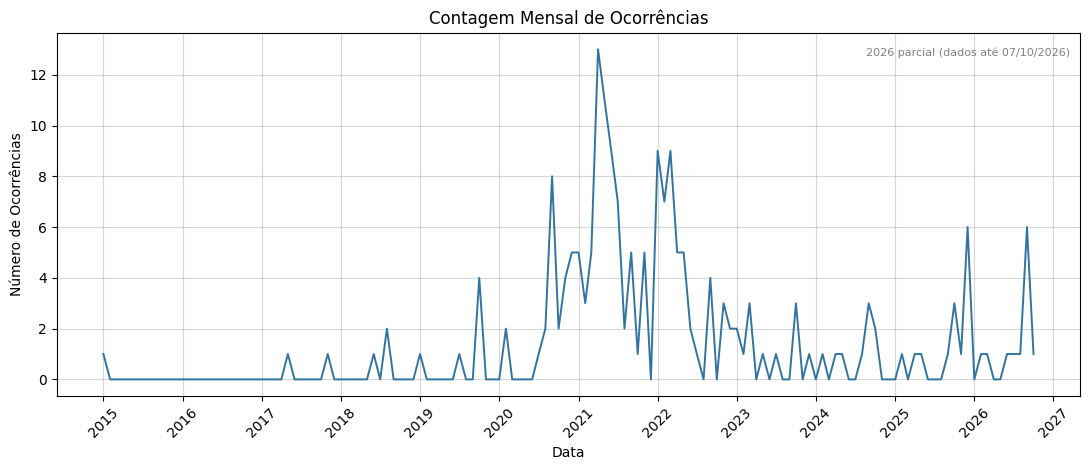

Pico mensal: 04/2021 com 13 ocorrências


Ano,2015,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
ocorrências,1,2,3,6,24,66,47,12,9,14,12


In [ ]:
mensal = base.set_index("Data").resample("MS").size()
tabelas["Fig1_mensal"] = mensal.rename("ocorrencias").reset_index()

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(mensal.index, mensal.values, color=COR_BARRA, lw=1.4)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.setp(ax.get_xticklabels(), rotation=45)
ax.grid(True, alpha=0.5)
ax.set_title("Contagem Mensal de Ocorrências")
ax.set_xlabel("Data"); ax.set_ylabel("Número de Ocorrências")
ax.annotate(f"{base['Data'].max().year} parcial (dados até {base['Data'].max():%d/%m/%Y})",
            xy=(0.99, 0.96), xycoords="axes fraction", ha="right", va="top", fontsize=8, color="gray")
plt.tight_layout(); salvar(fig, "fig1_contagem_mensal.png"); plt.show()

print("Pico mensal:", mensal.idxmax().strftime("%m/%Y"), "com", int(mensal.max()), "ocorrências")
display(base.groupby("Ano").size().rename("ocorrências").to_frame().T)

### Figura 2 — Distribuição das sanções

PNG salvo: /content/saida_analise/fig2_sancoes.png


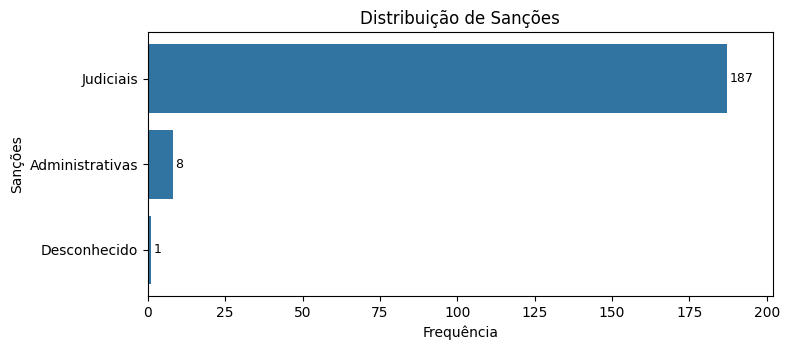

Sancao_pad,Judiciais,Administrativas,Desconhecido
registros,187,8,1


In [ ]:
sancoes = base["Sancao_pad"].value_counts()
tabelas["Fig2_sancoes"] = sancoes.rename("frequencia").reset_index()
barras_horizontais(sancoes, "Distribuição de Sanções", "Frequência", "Sanções", "fig2_sancoes.png", figsize=(8, 3.6))
display(sancoes.to_frame("registros").T)

### Figura 3 — Distribuição das leis (10 mais citadas)

PNG salvo: /content/saida_analise/fig3_leis.png


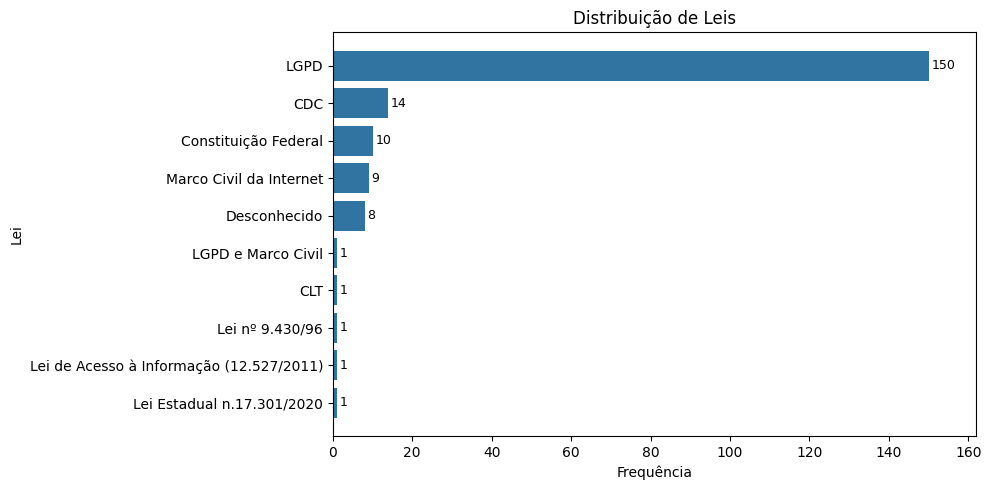

Lei_pad,LGPD,CDC,Constituição Federal,Marco Civil da Internet,Desconhecido,LGPD e Marco Civil,CLT,Lei nº 9.430/96,Lei de Acesso à Informação (12.527/2011),Lei Estadual n.17.301/2020
registros,150,14,10,9,8,1,1,1,1,1


In [ ]:
leis = base["Lei_pad"].value_counts()
tabelas["Fig3_leis"] = leis.rename("frequencia").reset_index()
barras_horizontais(leis.head(10), "Distribuição de Leis", "Frequência", "Lei", "fig3_leis.png", figsize=(10, 5))
display(leis.to_frame("registros").T)

### Figura 4 — Pareto dos artigos da LGPD

PNG salvo: /content/saida_analise/fig4_pareto_artigos.png


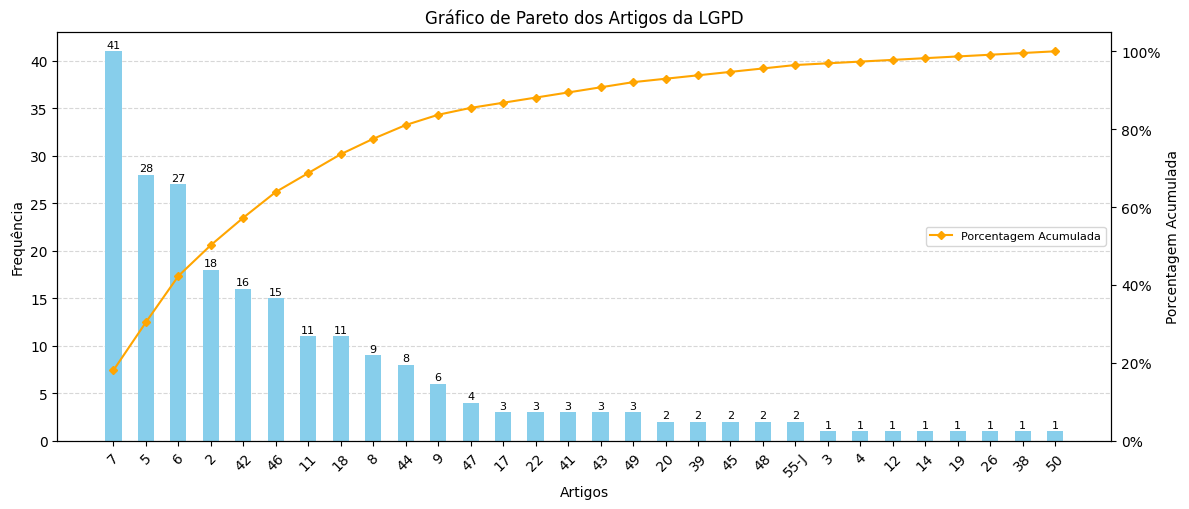

30 artigos distintos em 137 registros da LGPD; 5 mais citados: art. 7 (41), art. 5 (28), art. 6 (27), art. 2 (18), art. 42 (16)


In [ ]:
cont_art = Counter(a for lista in base["Artigos_LGPD"] for a in lista)       # 1 contagem por artigo em cada registro
chave = lambda kv: (-kv[1], int(re.match(r"\d+", kv[0]).group()), kv[0])
freq = pd.Series(dict(sorted(cont_art.items(), key=chave)))
acum = freq.cumsum() / freq.sum() * 100
tabelas["Fig4_pareto_artigos"] = pd.DataFrame({"artigo": freq.index, "frequencia": freq.values, "acumulado_%": acum.values.round(1)})

fig, ax = plt.subplots(figsize=(12, 5.2))
x = np.arange(len(freq))
barras = ax.bar(x, freq.values, width=0.5, color="skyblue")
ax.bar_label(barras, fontsize=8, padding=1)
ax.set_xticks(x); ax.set_xticklabels(freq.index, rotation=45)
ax.set_xlabel("Artigos"); ax.set_ylabel("Frequência")
ax.set_title("Gráfico de Pareto dos Artigos da LGPD")
ax.grid(axis="y", ls="--", alpha=0.5); ax.set_axisbelow(True)
ax2 = ax.twinx()
ax2.plot(x, acum.values, color="orange", marker="D", ms=4, label="Porcentagem Acumulada")
ax2.yaxis.set_major_formatter(PercentFormatter(100)); ax2.set_ylim(0, 105)
ax2.set_ylabel("Porcentagem Acumulada"); ax2.legend(loc="center right", fontsize=8)
plt.tight_layout(); salvar(fig, "fig4_pareto_artigos.png"); plt.show()

print(f"{len(freq)} artigos distintos em {int((base['Artigos_LGPD'].map(len) > 0).sum())} registros da LGPD; "
      f"5 mais citados: {', '.join(f'art. {a} ({n})' for a, n in freq.head(5).items())}")

### Figura 5 — Distribuição das condenações

PNG salvo: /content/saida_analise/fig5_condenacoes.png


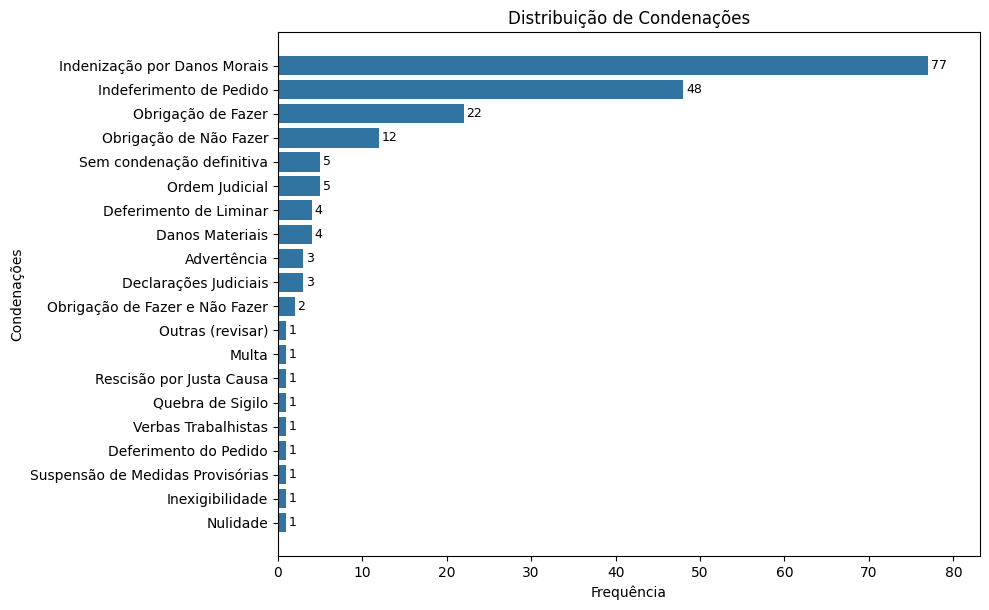

Total classificado: 194  |  registros sem condenação preenchida (fora do gráfico): 2


In [ ]:
cond = base["Condenacao_pad"].dropna().value_counts()
cond = cond.sort_values(ascending=False, kind="stable")
tabelas["Fig5_condenacoes"] = cond.rename("frequencia").reset_index()
barras_horizontais(cond, "Distribuição de Condenações", "Frequência", "Condenações", "fig5_condenacoes.png", figsize=(10, 6.2))
print(f"Total classificado: {int(cond.sum())}  |  registros sem condenação preenchida (fora do gráfico): {int(base['Condenacao_pad'].isna().sum())}")

### Figura 6 — 10 maiores segmentos

PNG salvo: /content/saida_analise/fig6_segmentos.png


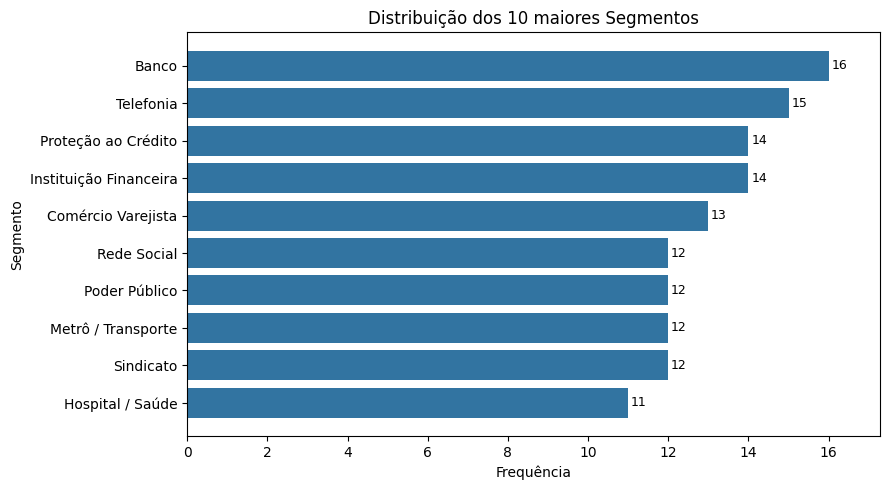

Segmentos distintos: 31  |  registros sem segmento identificado (fora do ranking): 1


In [ ]:
ranking_seg = base.loc[~base["Segmento_pad"].isin(SEG_EXCLUIR_RANKING), "Segmento_pad"].value_counts()
ranking_seg = ranking_seg.sort_index().sort_values(ascending=False, kind="stable")   # desempate determinístico (ordem alfabética)
corte = ranking_seg.iloc[TOP_N_SEGMENTOS - 1]
top_seg = ranking_seg[ranking_seg >= corte] if INCLUIR_EMPATES_TOP else ranking_seg.head(TOP_N_SEGMENTOS)          # inclui os empates na última posição (evita excluir um segmento de forma arbitrária)
n_top = len(top_seg)
rotulo_top = f"{TOP_N_SEGMENTOS} maiores Segmentos" + (f" (empate na {TOP_N_SEGMENTOS}ª posição: {n_top} segmentos)" if n_top > TOP_N_SEGMENTOS else "")
if n_top > TOP_N_SEGMENTOS: print(f"Atenção: empate na {TOP_N_SEGMENTOS}ª posição ({corte} registros); a figura mostra {n_top} segmentos.")
tabelas["Fig6_segmentos"] = ranking_seg.rename("frequencia").reset_index()
barras_horizontais(top_seg, f"Distribuição dos {rotulo_top}", "Frequência", "Segmento", "fig6_segmentos.png", figsize=(9, 5))
n_fora = int(base["Segmento_pad"].isin(SEG_EXCLUIR_RANKING).sum())
print(f"Segmentos distintos: {len(ranking_seg)}  |  registros sem segmento identificado (fora do ranking): {n_fora}")

### Figura 7 — Condenações nos 10 maiores segmentos

PNG salvo: /content/saida_analise/fig7_condenacoes_por_segmento.png


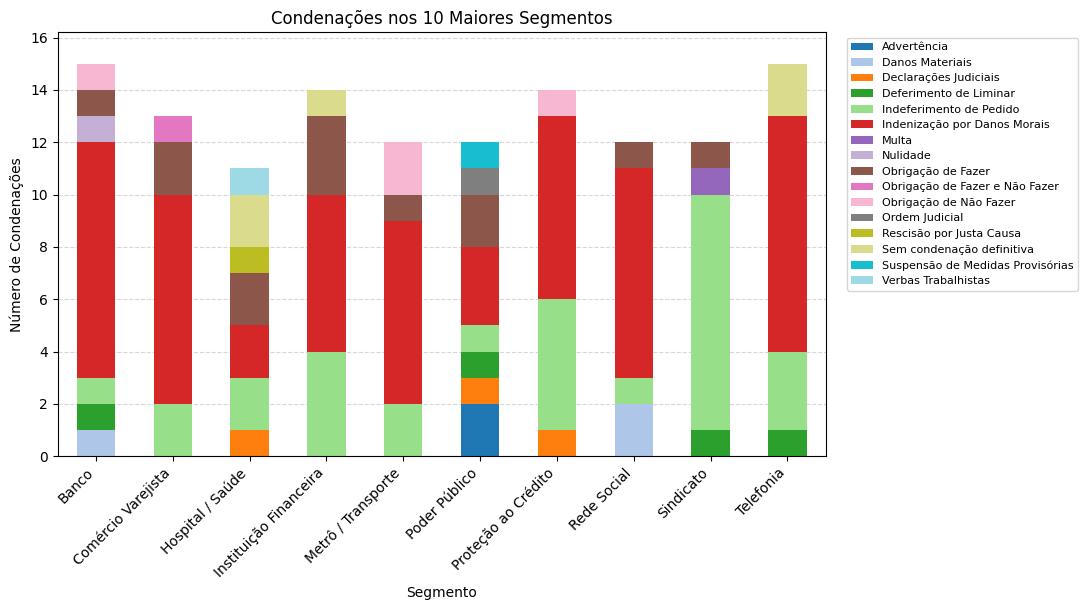

Condenacao_pad,Advertência,Danos Materiais,Declarações Judiciais,Deferimento de Liminar,Indeferimento de Pedido,Indenização por Danos Morais,Multa,Nulidade,Obrigação de Fazer,Obrigação de Fazer e Não Fazer,Obrigação de Não Fazer,Ordem Judicial,Rescisão por Justa Causa,Sem condenação definitiva,Suspensão de Medidas Provisórias,Verbas Trabalhistas
Segmento_pad,,,,,,,,,,,,,,,,
Banco,0,1,0,1,1,9,0,1,1,0,1,0,0,0,0,0
Comércio Varejista,0,0,0,0,2,8,0,0,2,1,0,0,0,0,0,0
Hospital / Saúde,0,0,1,0,2,2,0,0,2,0,0,0,1,2,0,1
Instituição Financeira,0,0,0,0,4,6,0,0,3,0,0,0,0,1,0,0
Metrô / Transporte,0,0,0,0,2,7,0,0,1,0,2,0,0,0,0,0
Poder Público,2,0,1,1,1,3,0,0,2,0,0,1,0,0,1,0
Proteção ao Crédito,0,0,1,0,5,7,0,0,0,0,1,0,0,0,0,0
Rede Social,0,2,0,0,1,8,0,0,1,0,0,0,0,0,0,0
Sindicato,0,0,0,1,9,0,1,0,1,0,0,0,0,0,0,0


In [ ]:
sub = base[base["Segmento_pad"].isin(top_seg.index) & base["Condenacao_pad"].notna()]
cruz = pd.crosstab(sub["Segmento_pad"], sub["Condenacao_pad"])
cruz = cruz.loc[sorted(cruz.index, key=norm), sorted(cruz.columns, key=norm)]   # ordem alfabética, como no artigo
tabelas["Fig7_segmento_x_condenacao"] = cruz.reset_index()

fig, ax = plt.subplots(figsize=(11, 6.2))
cruz.plot(kind="bar", stacked=True, colormap="tab20", ax=ax, width=0.5)
ax.set_title(f"Condenações nos {n_top} maiores segmentos" + (" (inclui empate)" if n_top > TOP_N_SEGMENTOS else ""))
ax.set_xlabel("Segmento"); ax.set_ylabel("Número de Condenações")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.grid(axis="y", ls="--", alpha=0.5); ax.set_axisbelow(True)
ax.set_ylim(0, cruz.sum(axis=1).max() * 1.08)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8, frameon=True)
plt.tight_layout(); salvar(fig, "fig7_condenacoes_por_segmento.png"); plt.show()
display(cruz)

## 7. Validação contra os números do artigo

Aplica **as mesmas regras** à planilha cortada na data de `CORTE_COMPARACAO_ARTIGO`. Pequenas diferenças são esperadas, porque a planilha atual tem linhas que o artigo não tinha (o artigo usou 160 registros) e porque há textos compostos que o artigo pode ter classificado de outra forma (por exemplo, dano moral coletivo).

- **Δ = 0** → idêntico ao artigo.
- Diferenças grandes indicam um problema de padronização.

In [ ]:
ARTIGO = {
 "Fig. 2 – Sanções": {"Judiciais": 155, "Administrativas": 4, "Desconhecido": 1},
 "Fig. 3 – Leis": {"LGPD": 123, "CDC": 13, "Marco Civil da Internet": 9, "Constituição Federal": 9, "LGPD e Marco Civil": 1,
                   "CLT": 1, "Lei nº 9.430/96": 1, "Lei de Acesso à Informação (12.527/2011)": 1,
                   "Lei Estadual n.17.301/2020": 1, "Desconhecido": 1},
 "Fig. 4 – Artigos LGPD": {"7": 24, "6": 22, "5": 18, "2": 16, "46": 13, "42": 11, "11": 9, "18": 8, "44": 7, "49": 3,
                           "22": 3, "43": 3, "17": 3, "41": 3, "48": 2, "8": 2, "45": 2, "20": 2, "4": 1, "55-J": 1},
 "Fig. 5 – Condenações": {"Indenização por Danos Morais": 61, "Indeferimento de Pedido": 41, "Obrigação de Fazer": 18,
                          "Obrigação de Não Fazer": 11, "Ordem Judicial": 5, "Danos Materiais": 4, "Deferimento de Liminar": 4,
                          "Advertência": 3, "Declarações Judiciais": 2, "Obrigação de Fazer e Não Fazer": 1, "Inexigibilidade": 1,
                          "Suspensão de Medidas Provisórias": 1, "Verbas Trabalhistas": 1, "Deferimento do Pedido": 1,
                          "Quebra de Sigilo": 1, "Multa": 1, "Rescisão por Justa Causa": 1, "Nulidade": 1},
 "Fig. 6 – Segmentos": {"Banco": 14, "Sindicato": 12, "Rede Social": 9, "Telefonia": 7, "Instituição Financeira": 6,
                        "Vendas On-Line": 6, "Hospital": 5, "Comércio Varejista": 4, "Metrô": 4, "Serviços de Internet": 3},
}

corte = df.loc[df["Data"] <= pd.Timestamp(CORTE_COMPARACAO_ARTIGO)]
if EXCLUIR_SINALIZADOS: corte = corte.loc[~corte["Sinalizado"]]
# Segmentos: o artigo NÃO unificou famílias; por isso a validação usa o modo "conservadora"
seg_validacao = corte["Segmento"].map(lambda v: padronizar_segmento(v, "conservadora"))
print(f"Planilha atual até {pd.Timestamp(CORTE_COMPARACAO_ARTIGO):%d/%m/%Y}: {len(corte)} registros  (artigo: 160)\n")

calc = {
 "Fig. 2 – Sanções": corte["Sancao_pad"].value_counts(),
 "Fig. 3 – Leis": corte["Lei_pad"].value_counts(),
 "Fig. 4 – Artigos LGPD": pd.Series(Counter(a for l in corte["Artigos_LGPD"] for a in l)),
 "Fig. 5 – Condenações": corte["Condenacao_pad"].value_counts(),
 "Fig. 6 – Segmentos": seg_validacao[~seg_validacao.isin(SEG_EXCLUIR_RANKING)].value_counts(),
}
linhas = []
for fig_nome, ref in ARTIGO.items():
    for item, valor_artigo in ref.items():
        valor_calc = int(calc[fig_nome].get(item, 0))
        linhas.append((fig_nome, item, valor_artigo, valor_calc, valor_calc - valor_artigo))
validacao = pd.DataFrame(linhas, columns=["Figura", "Categoria", "Artigo", "Notebook", "Δ"])

resumo = validacao.groupby("Figura").agg(categorias=("Categoria", "size"), iguais=("Δ", lambda s: int((s == 0).sum())),
                                          soma_artigo=("Artigo", "sum"), soma_notebook=("Notebook", "sum"))
display(resumo)
display(validacao[validacao["Δ"] != 0].reset_index(drop=True))

Planilha atual até 30/04/2024: 163 registros  (artigo: 160)



,categorias,iguais,soma_artigo,soma_notebook
Figura,,,,
Fig. 2 – Sanções,3,2,160,163
Fig. 3 – Leis,10,9,160,163
Fig. 4 – Artigos LGPD,20,12,153,173
Fig. 5 – Condenações,18,15,158,161
Fig. 6 – Segmentos,10,10,70,70


,Figura,Categoria,Artigo,Notebook,Δ
0,Fig. 2 – Sanções,Judiciais,155,158,3
1,Fig. 3 – Leis,LGPD,123,126,3
2,Fig. 4 – Artigos LGPD,7,24,30,6
3,Fig. 4 – Artigos LGPD,6,22,25,3
4,Fig. 4 – Artigos LGPD,5,18,22,4
5,Fig. 4 – Artigos LGPD,2,16,17,1
6,Fig. 4 – Artigos LGPD,42,11,12,1
7,Fig. 4 – Artigos LGPD,11,9,11,2
8,Fig. 4 – Artigos LGPD,18,8,10,2
9,Fig. 4 – Artigos LGPD,8,2,3,1


## 8. Exportar resultados
Gera `tabelas_apdados.xlsx` (dados de cada figura, auditorias e validação), `base_padronizada.csv` e um `.zip` com tudo.

In [ ]:
caminho_xlsx = os.path.join(PASTA_SAIDA, "tabelas_apdados.xlsx")
with pd.ExcelWriter(caminho_xlsx) as w:
    for nome, t in tabelas.items():
        t.to_excel(w, sheet_name=nome[:31], index=False)
    validacao.to_excel(w, sheet_name="Validacao_vs_artigo", index=False)
    aud_cond.to_excel(w, sheet_name="Auditoria_condenacoes", index=False)
    aud_seg.to_excel(w, sheet_name="Auditoria_segmentos", index=False)
    aud_lei.to_excel(w, sheet_name="Auditoria_leis", index=False)
    artigos_recuperados.astype(str).to_excel(w, sheet_name="Artigos_recuperados_data", index=False)
    revisar.to_excel(w, sheet_name="Condenacoes_a_revisar", index=False)

colunas = ["Data", "Ano", "Estado", "Emissor", "Sanções", "Sancao_pad", "Lei", "Lei_pad", "Artigo", "Artigos_LGPD",
           "Condenações", "Condenacao_pad", "Segmento", "Segmento_pad", "Sinalizado", "LINK"]
base_export = df[colunas].copy()
base_export["Artigos_LGPD"] = base_export["Artigos_LGPD"].map(lambda l: ", ".join(l))
base_export["Artigo"] = base_export["Artigo"].astype(str)
base_export.to_csv(os.path.join(PASTA_SAIDA, "base_padronizada.csv"), index=False, encoding="utf-8-sig")

zip_path = PASTA_SAIDA + ".zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for arq in sorted(os.listdir(PASTA_SAIDA)):
        z.write(os.path.join(PASTA_SAIDA, arq), arcname=arq)
print("Arquivos gerados:", *sorted(os.listdir(PASTA_SAIDA)), sep="\n  • ")

try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("\nFora do Colab: os arquivos estão na pasta", PASTA_SAIDA)

Arquivos gerados:
  • base_padronizada.csv
  • fig1_contagem_mensal.png
  • fig2_sancoes.png
  • fig3_leis.png
  • fig4_pareto_artigos.png
  • fig5_condenacoes.png
  • fig6_segmentos.png
  • fig7_condenacoes_por_segmento.png
  • tabelas_apdados.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Observações para o texto do trabalho
- A unidade de contagem é a **linha da planilha**, como no artigo. Várias linhas podem se referir a processos parecidos (por exemplo, 5 REsp. do STJ em 09/12/2025).
- **2026 é um ano parcial.**
- Registros 2025–26 trazem observações do tipo *"confirmar no inteiro teor"*. A coluna `Sinalizado` isola os casos que a própria planilha marca como inadequados.
- As categorias de condenação e segmento foram padronizadas por regras **auditáveis**. A seção 5 mostra o mapeamento completo, e os casos `Outras` pedem classificação manual.
- Dano moral coletivo e presumido foram somados a *Indenização por Danos Morais*. Para separá-los, crie uma regra em `REGRAS_ESPECIAIS` antes da análise por orações.

## 10. Análises complementares

Complementam as sete figuras reproduzidas do artigo. Usam a mesma base tratada (`base`), sem adicionar registros. Foram mantidas só as análises que trazem uma perspectiva nova; as demais foram descartadas (ver o início do notebook).

**Atenção:** os resultados descrevem os registros disponíveis na planilha, não a totalidade das decisões ou violações relacionadas à LGPD no Brasil.


### Análise 10.1 — Diversidade de artigos da LGPD por segmento

**Pergunta:** quais segmentos citam maior variedade de artigos da LGPD?

O número de artigos distintos cresce com o número de registros; por isso a tabela traz também os **registros com artigos**, as **citações** e a **razão artigos distintos ÷ registros**. Só entram segmentos com pelo menos `MIN_REG_DIVERSIDADE` registros que citam artigos da LGPD.


In [ ]:
linhas = []
for _, row in base.iterrows():
    seg = row.get("Segmento_pad")
    if pd.isna(seg) or seg in SEG_EXCLUIR_RANKING:
        continue
    for art in row.get("Artigos_LGPD", []):
        linhas.append((row.name, seg, str(art)))
artigos_long = pd.DataFrame(linhas, columns=["Registro", "Segmento", "Artigo"])

if artigos_long.empty:
    print("Não há artigos da LGPD identificados para esta análise.")
else:
    div = (artigos_long.groupby("Segmento")
           .agg(Registros_com_artigos=("Registro", "nunique"),
                Artigos_distintos=("Artigo", "nunique"),
                Citacoes=("Artigo", "size")))
    div["Razao_distintos_por_registro"] = (div["Artigos_distintos"] / div["Registros_com_artigos"]).round(2)
    div = div.sort_values(["Artigos_distintos", "Citacoes"], ascending=False)
    tabelas["A10_1_diversidade_artigos"] = div.reset_index()
    sel = div[div["Registros_com_artigos"] >= MIN_REG_DIVERSIDADE].head(15)
    display(sel)

    s = sel["Artigos_distintos"].sort_values()
    rot = [f"{i} (n={int(sel.loc[i, 'Registros_com_artigos'])})" for i in s.index]
    fig, ax = plt.subplots(figsize=(11, 7))
    barras = ax.barh(rot, s.values, color=COR_BARRA)
    ax.bar_label(barras, padding=2, fontsize=9)
    ax.set_title("Diversidade de artigos da LGPD por segmento")
    ax.set_xlabel("Quantidade de artigos distintos")
    ax.set_ylabel("Segmento (n = registros que citam artigos da LGPD)")
    ax.grid(axis="x", linestyle="--", alpha=.3); ax.set_axisbelow(True)
    plt.tight_layout(); salvar(fig, "analise10_1_diversidade_artigos_segmento.png"); plt.show()


### Análise 10.2 — Artigos da LGPD citados em conjunto

**Pergunta:** quais pares de artigos aparecem juntos com maior frequência no mesmo registro?

Cada registro conta no máximo uma vez por par, e só entram registros com pelo menos dois artigos identificados. O resultado indica **coocorrência**, não relação jurídica nem causalidade. As contagens são pequenas e devem ser lidas como descritivas.


In [ ]:
from itertools import combinations

def chave_num(a):
    m = re.match(r"(\d+)", str(a)); return (int(m.group(1)) if m else 10**6, str(a))

contagem_pares = Counter(); registros_com_pares = 0
for lista in base["Artigos_LGPD"]:
    unicos = sorted(set(map(str, lista)), key=chave_num)      # ordem NUMÉRICA (5 antes de 11)
    if len(unicos) >= 2:
        registros_com_pares += 1
        contagem_pares.update(combinations(unicos, 2))

if not contagem_pares:
    print("Não foram encontrados registros com dois ou mais artigos identificados.")
else:
    pares = pd.DataFrame([(a, b, n) for (a, b), n in contagem_pares.most_common()],
                         columns=["Artigo_1", "Artigo_2", "Registros_juntos"])
    pares["Percentual_dos_registros_com_pares"] = (pares["Registros_juntos"] / registros_com_pares * 100).round(1)
    tabelas["A10_2_pares_artigos"] = pares
    print(f"Registros com 2+ artigos da LGPD: {registros_com_pares}  |  pares distintos: {len(pares)}")
    display(pares.head(15))

    top = pares.head(15).copy()
    top["Par"] = "Art. " + top["Artigo_1"] + " + Art. " + top["Artigo_2"]
    s = top.set_index("Par")["Registros_juntos"].iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, 7))
    barras = ax.barh(s.index, s.values, color=COR_BARRA)
    ax.bar_label(barras, padding=2, fontsize=9)
    ax.set_title("Pares de artigos da LGPD mais citados em conjunto")
    ax.set_xlabel(f"Registros em que aparecem juntos (de {registros_com_pares} registros com 2+ artigos)")
    ax.set_ylabel("Par de artigos")
    ax.grid(axis="x", linestyle="--", alpha=.3); ax.set_axisbelow(True)
    plt.tight_layout(); salvar(fig, "analise10_2_pares_artigos.png"); plt.show()


### Análise 10.3 — Valores de penalidade (somente valores em R$ interpretáveis)

**Pergunta:** qual o perfil dos valores financeiros registrados e como variam entre segmentos?

A coluna `Valor [R$]` é texto livre. Antes de qualquer estatística, cada célula é **classificada**:

| Categoria | Exemplo | Entra na análise? |
|---|---|---|
| Valor em R$ | `R$ 5.000,00` | **sim** |
| Não monetário | `200 UFESPs`, `3 salários da autora` | não |
| Pedido não concedido | `R$ 25.000,00 pedidos; não concedidos` | não |
| Multa diária/teto ou valor ambíguo | `R$ 300,00 por dia, limitada a R$ 10.000,00` | não |
| Sem valor informado | `Sem indenização`, vazio | não |

Como há valores extremos, usa-se **mediana e quartis** (não média) e **escala logarítmica**. O gráfico mostra o **n** de cada segmento e só inclui segmentos com pelo menos `MIN_N_VALORES` valores.


In [ ]:
def converter_valor_monetario(valor):
    if pd.isna(valor): return np.nan
    if isinstance(valor, (int, float, np.integer, np.floating)): return float(valor)
    s = re.sub(r"[^0-9,.\-]", "", str(valor).strip())
    if not s: return np.nan
    if "," in s: s = s.replace(".", "").replace(",", ".")      # padrão brasileiro 1.234,56
    try: return float(s)
    except ValueError: return np.nan

def classificar_valor(v):
    """Retorna (categoria, valor em R$ ou NaN)."""
    if pd.isna(v): return "Sem valor informado", np.nan
    if isinstance(v, (int, float, np.integer, np.floating)):
        return ("Valor em R$", float(v)) if v > 0 else ("Sem valor informado", np.nan)
    t = norm(v)
    if not re.search(r"\d", t):                                 return "Sem valor informado", np.nan
    if re.search(r"ufesp|salario", t):                          return "Não monetário (UFESP/salários)", np.nan
    if re.search(r"pedid|nao concedid", t):                     return "Pedido não concedido", np.nan
    if re.search(r"nenhum valor contra|por dia|limitad|diari", t): return "Multa diária/teto ou valor ambíguo", np.nan
    x = converter_valor_monetario(v)
    return ("Valor em R$", x) if (x == x and x > 0) else ("Sem valor informado", np.nan)

perfil = base.copy()
res = perfil["Valor [R$]"].map(classificar_valor)
perfil["Valor_categoria"] = [a for a, _ in res]
perfil["Valor_R$"] = [b for _, b in res]

cat_valor = perfil["Valor_categoria"].value_counts().rename("registros").to_frame()
cat_valor["%"] = (cat_valor["registros"] / len(perfil) * 100).round(1)
print(f"Registros na base: {len(perfil)}")
display(cat_valor)
tabelas["A10_3_classificacao_valores"] = cat_valor.reset_index()

com_valor = perfil[perfil["Valor_categoria"] == "Valor em R$"].copy()
print(f"\n>>> Valores em R$ usados na análise: n = {len(com_valor)} ({len(com_valor)/len(perfil)*100:.0f}% dos registros)")

resumo = com_valor["Valor_R$"].describe(percentiles=[.25, .5, .75, .9]).round(2).to_frame("Valor_R$")
display(resumo)
tabelas["A10_3_resumo_valores"] = resumo.reset_index()

# Valores extremos — conferir no processo original antes de citar
extremos = (com_valor.sort_values("Valor_R$", ascending=False)
            [["Data", "Estado", "Emissor", "Segmento_pad", "Valor [R$]", "Valor_R$", "LINK"]].head(6))
print("\nMaiores valores (conferir no processo original):")
display(extremos)
tabelas["A10_3_valores_extremos"] = extremos

g = com_valor.groupby("Segmento_pad")["Valor_R$"]
por_seg = pd.DataFrame({"n": g.count(), "Q1": g.quantile(.25), "Mediana": g.median(),
                        "Q3": g.quantile(.75), "Maximo": g.max()}).sort_values("n", ascending=False).round(2)
tabelas["A10_3_valores_por_segmento"] = por_seg.reset_index()
display(por_seg.head(15))

sel = por_seg[por_seg["n"] >= MIN_N_VALORES].head(10)
dados = [com_valor.loc[com_valor["Segmento_pad"] == s, "Valor_R$"].values for s in sel.index]
rot = [f"{s}\n(n={int(sel.loc[s, 'n'])})" for s in sel.index]
fig, ax = plt.subplots(figsize=(12, 6.2))
try:    ax.boxplot(dados, tick_labels=rot, showfliers=False)
except TypeError: ax.boxplot(dados, labels=rot, showfliers=False)
rng = np.random.default_rng(42)
for i, d in enumerate(dados, start=1):                      # pontos individuais (inclui os extremos)
    ax.scatter(rng.normal(i, 0.05, len(d)), d, s=14, alpha=.55, color="#3274A1", zorder=3)
ax.set_yscale("log")
ax.set_title("Valores de penalidade em R$ por segmento (escala logarítmica)")
ax.set_ylabel("Valor (R$, escala log)"); ax.set_xlabel("Segmento (n = registros com valor em R$)")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.grid(axis="y", linestyle="--", alpha=.3)
plt.tight_layout(); salvar(fig, "analise10_3_valores_por_segmento.png"); plt.show()


### Análise 10.4 — Leis citadas por segmento

**Pergunta:** quais leis, além da LGPD, aparecem em cada segmento?

Leis com menos de `MIN_REG_LEI` registros são agrupadas em **Outras leis**, e a categoria *Desconhecido* aparece como **Lei não identificada**. A tabela mostra também o percentual de registros **que não citam a LGPD** em cada segmento.


In [ ]:
al = base.dropna(subset=["Segmento_pad", "Lei_pad"]).copy()
al = al[~al["Segmento_pad"].isin(SEG_EXCLUIR_RANKING)]

contagem_leis = al["Lei_pad"].value_counts()
raras = set(contagem_leis[(contagem_leis < MIN_REG_LEI) & (contagem_leis.index != "Desconhecido")].index)
def lei_grupo(l):
    if l == "Desconhecido": return "Lei não identificada"
    return "Outras leis" if l in raras else l
al["Lei_grupo"] = al["Lei_pad"].map(lei_grupo)
print("Leis agrupadas em 'Outras leis':", sorted(raras))

cruz = pd.crosstab(al["Segmento_pad"], al["Lei_grupo"])
top12 = al["Segmento_pad"].value_counts().head(12).index
cruz12 = cruz.reindex(top12)
cruz12 = cruz12[["LGPD"] + [c for c in cruz12.columns if c != "LGPD"]]      # LGPD embaixo da pilha
cruz12["Total"] = cruz12.sum(axis=1)
cruz12["% sem LGPD"] = ((cruz12["Total"] - cruz12["LGPD"]) / cruz12["Total"] * 100).round(0)
display(cruz12)
tabelas["A10_4_leis_por_segmento"] = cruz.reset_index()
tabelas["A10_4_top12_com_percentual"] = cruz12.reset_index()

plot = cruz12.drop(columns=["Total", "% sem LGPD"])
ax = plot.plot(kind="bar", stacked=True, figsize=(14, 7.5), colormap="tab20", width=0.7)
ax.set_title("Leis citadas nos 12 maiores segmentos")
ax.set_xlabel("Segmento"); ax.set_ylabel("Quantidade de registros")
ax.legend(title="Lei", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=.3); ax.set_axisbelow(True)
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
salvar(plt.gcf(), "analise10_4_leis_por_segmento.png"); plt.show()


### Análise 10.5 — Sensibilidade à origem dos registros

**Pergunta:** os resultados mudam quando se consideram só os registros da APDados?

A base tem registros da APDados (link "Externo") e registros **complementares**, incluídos depois (decisões de tribunais e páginas da ANPD), cujos campos foram preenchidos a partir de resumos e **não foram conferidos no inteiro teor**. A tabela compara a base completa com cada origem.


In [ ]:
def _pares(x):
    c = Counter()
    for lista in x["Artigos_LGPD"]:
        u = sorted(set(map(str, lista)), key=chave_num)
        if len(u) >= 2: c.update(combinations(u, 2))
    return c

def indicadores(x):
    n = len(x); cont = x["Condenacao_pad"].value_counts()
    arts = Counter(a for l in x["Artigos_LGPD"] for a in l)
    vals = pd.Series([classificar_valor(v)[1] for v in x["Valor [R$]"]]).dropna()
    pares = _pares(x).most_common(3)
    seg = x.loc[~x["Segmento_pad"].isin(SEG_EXCLUIR_RANKING), "Segmento_pad"].value_counts().head(4)
    return {
        "Registros": n,
        "Sanções judiciais (%)": round((x["Sancao_pad"] == "Judiciais").mean() * 100, 1),
        "Registros com a LGPD (%)": round((x["Lei_pad"] == "LGPD").mean() * 100, 1),
        "Indenização por danos morais (%)": round(cont.get("Indenização por Danos Morais", 0) / n * 100, 1),
        "Indeferimento de pedido (%)": round(cont.get("Indeferimento de Pedido", 0) / n * 100, 1),
        "Artigos mais citados": ", ".join(f"{a} ({c})" for a, c in arts.most_common(6)),
        "Valores em R$ (n)": len(vals),
        "Mediana dos valores (R$)": float(vals.median()) if len(vals) else np.nan,
        "Sanções administrativas aplicadas": int((x["Sancao_pad"] == "Administrativas").sum()),
        "Processos/medidas administrativas": int(x["Sancao_pad"].str.startswith("Administrativas (").sum()),
        "Registros com 2+ artigos": int(sum(len(l) >= 2 for l in x["Artigos_LGPD"])),
        "Pares de artigos mais frequentes": ", ".join(f"{a}+{b} ({c})" for (a, b), c in pares),
        "Maiores segmentos": ", ".join(f"{s} ({c})" for s, c in seg.items()),
    }

sens = pd.DataFrame({
    "Base completa": indicadores(base),
    "Só APDados": indicadores(base[base["Fonte"] == "APDados"]),
    "Só complementares": indicadores(base[base["Fonte"] == "Complementar"]),
})
display(sens)
tabelas["A10_5_sensibilidade_fonte"] = sens.reset_index(names="Indicador")

por_ano = pd.crosstab(base["Ano"], base["Fonte"])
print("\nRegistros por ano e origem:"); display(por_ano.T)
tabelas["A10_5_ano_por_fonte"] = por_ano.reset_index()

top_seg_fonte = pd.crosstab(base["Segmento_pad"], base["Fonte"]).assign(Total=lambda t: t.sum(axis=1)).sort_values("Total", ascending=False).head(12)
print("\nMaiores segmentos por origem:"); display(top_seg_fonte)
tabelas["A10_5_segmentos_por_fonte"] = top_seg_fonte.reset_index()


## 11. Exportar resultados (versão final)

Repete a exportação da seção 8 **depois** das análises complementares, para que as tabelas da seção 10 e o mapeamento de segmentos também entrem no `.xlsx` e no `.zip`. Gera ainda `mapeamento_segmentos.csv` (rótulo original → grupo), útil como apêndice e para o repositório.


In [ ]:
aud_seg.to_csv(os.path.join(PASTA_SAIDA, "mapeamento_segmentos.csv"), index=False, encoding="utf-8-sig")
caminho_xlsx = os.path.join(PASTA_SAIDA, "tabelas_apdados.xlsx")
with pd.ExcelWriter(caminho_xlsx) as w:
    for nome, t in tabelas.items():
        t.to_excel(w, sheet_name=nome[:31], index=False)
    validacao.to_excel(w, sheet_name="Validacao_vs_artigo", index=False)
    aud_cond.to_excel(w, sheet_name="Auditoria_condenacoes", index=False)
    aud_seg.to_excel(w, sheet_name="Auditoria_segmentos", index=False)
    aud_lei.to_excel(w, sheet_name="Auditoria_leis", index=False)
    artigos_recuperados.astype(str).to_excel(w, sheet_name="Artigos_recuperados_data", index=False)
    revisar.to_excel(w, sheet_name="Condenacoes_a_revisar", index=False)

colunas = ["Data", "Ano", "Estado", "Emissor", "Sanções", "Sancao_pad", "Lei", "Lei_pad", "Artigo", "Artigos_LGPD",
           "Condenações", "Condenacao_pad", "Segmento", "Segmento_pad", "Sinalizado", "LINK"]
base_export = df[colunas].copy()
base_export["Artigos_LGPD"] = base_export["Artigos_LGPD"].map(lambda l: ", ".join(l))
base_export["Artigo"] = base_export["Artigo"].astype(str)
base_export.to_csv(os.path.join(PASTA_SAIDA, "base_padronizada.csv"), index=False, encoding="utf-8-sig")

zip_path = PASTA_SAIDA + ".zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for arq in sorted(os.listdir(PASTA_SAIDA)):
        z.write(os.path.join(PASTA_SAIDA, arq), arcname=arq)
print("Arquivos gerados:", *sorted(os.listdir(PASTA_SAIDA)), sep="\n  • ")

try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("\nFora do Colab: os arquivos estão na pasta", PASTA_SAIDA)